# Лабораторная работа 2 — часть «Деревья и ансамбли в sklearn по CRISP-DM»

## Цель

Построить воспроизводимый классификационный конвейер для оценки
вероятности оформления срочного вклада до звонка клиенту. Работа
демонстрирует полный цикл CRISP-DM: постановку задачи, аудит данных,
подготовку, моделирование, оценку и выводы для использования модели.

**Результат.** В конце должна быть таблица baseline- и настроенных
моделей, оценённая по отложенной test-выборке, а также краткая
модельная карточка с ограничениями.

Теория: [лонгрид о деревьях](../06-decision-trees/decision-trees.md),
[деревья sklearn](https://scikit-learn.org/stable/modules/tree.html),
[ансамбли sklearn](https://scikit-learn.org/stable/modules/ensemble.html).

## 0. Правила честного эксперимента

Используйте один `RANDOM_STATE` во всех случайных процедурах. Сначала
отделите 20% наблюдений в `test`; до финальной оценки не смотрите на
её метрики. Все операции, которые учатся по данным (импутация,
кодирование категорий), должны жить внутри `Pipeline` и обучаться
заново в каждом фолде кросс-валидации.

`duration` — длительность завершившегося звонка. Для задачи «кому
позвонить» этот признак неизвестен, поэтому его нельзя включать в
основную модель. В разделе 8 вы увидите контролируемый пример утечки,
но не будете использовать его при выборе итоговой модели.

In [1]:
from pathlib import Path
from copy import deepcopy

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import loguniform
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import BaggingClassifier, GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
TEST_SIZE = 0.20
CV = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
TUNING_ITERATIONS = 6

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 40)

## 1. Business understanding

**Решение.** До начала телефонной кампании ранжировать клиентов по
вероятности оформления вклада.

**Положительный класс.** `y = yes`.

**Критерий выбора.** Положительный класс составляет меньшинство,
поэтому основной критерий кросс-валидации — average precision
(площадь под precision–recall-кривой). На финальном test дополнительно
покажите ROC-AUC, precision, recall, F1 и balanced accuracy. Порог
`0.5` служит только единым учебным ориентиром: рабочий порог требует
стоимости звонка, выгоды от вклада и допустимого риска.

Перед выполнением познакомьтесь с [типичными утечками данных в
sklearn](https://scikit-learn.org/stable/common_pitfalls.html).

In [6]:
# Загрузка данных
data_path = Path("data/bank-full.csv")
raw_data = pd.read_csv(data_path, sep=";")

print("Размер исходной таблицы:", raw_data.shape)
display(raw_data.head())

Размер исходной таблицы: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 2. Data understanding

Сначала подтвердите, что таблица соответствует data card: проверьте
размеры, типы, пропуски, дубликаты и распределение цели. Затем
постройте как минимум один график распределения числового признака и
один график частот категориального признака, разделённый по цели.

Ожидаемый результат — не «красивый график», а список наблюдений,
влияющих на подготовку: дисбаланс `y`, код `pdays=-1`, категориальные
значения `unknown` и признак `duration`, недоступный в момент решения.

In [7]:
# TODO: создайте audit_table с dtype, числом пропусков и числом уникальных значений.
# TODO: выведите количество полных дубликатов и нормированное распределение y.
# TODO: постройте два содержательных графика EDA с подписями на русском.
def prepare_domain_features(frame: pd.DataFrame, include_duration: bool = False) -> tuple[pd.DataFrame, pd.Series]:
    df = frame.copy()
    
    # Кодируем целевую переменную y: yes -> 1, no -> 0
    y = df["y"].apply(lambda val: 1 if val == "yes" else 0)
    
    # Исключаем целевой столбец
    df = df.drop(columns=["y"])
    
    # Исключаем duration по умолчанию (для предотвращения утечки)
    if not include_duration and "duration" in df.columns:
        df = df.drop(columns=["duration"])
        
    # Добавляем признак: был ли прошлый контакт
    if "pdays" in df.columns:
        df["previously_contacted"] = (df["pdays"] != -1).astype(int)
        # Заменяем -1 на NaN для корректной импутации числовых признаков
        df["pdays"] = df["pdays"].replace(-1, np.nan)
        
    return df, y

# Готовим основные X и y без duration
X_raw, y_raw = prepare_domain_features(raw_data, include_duration=False)

# Стратифицированное разбиение на train_val и test (80 / 20)
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X_raw, y_raw, test_size=TEST_SIZE, stratify=y_raw, random_state=RANDOM_STATE
)

# Выделяем числовые и категориальные столбцы
numeric_features = X_train_val.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = X_train_val.select_dtypes(include=["object", "category", "str"]).columns.tolist()

print("Числовые признаки:", numeric_features)
print("Категориальные признаки:", categorical_features)

Числовые признаки: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous', 'previously_contacted']
Категориальные признаки: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


## 3. Data preparation

Выполните детерминированную предметную подготовку до разбиения:

1. отделите `y` и закодируйте `yes/no` как `1/0`;
2. исключите `duration` из основной задачи;
3. добавьте `previously_contacted`: был ли прошлый контакт;
4. замените `pdays=-1` на пропуск, поскольку это не «минус один день»;
5. сохраните `unknown` как наблюдаемую категорию.

После этого сделайте stratified split. Импутация и one-hot encoding
нельзя выполнять на всей таблице до split: их параметры должны
извлекаться только из обучающего фолда. Поэтому построим общий
`ColumnTransformer` и поместим его в `Pipeline`.

In [8]:
# TODO: реализуйте prepare_domain_features(frame, include_duration=False).
# Функция должна возвращать X и y; не менять переданный DataFrame.
# TODO: вызовите функцию, выполните train/test split со stratify=y и random_state=RANDOM_STATE.
def prepare_domain_features(frame: pd.DataFrame, include_duration: bool = False) -> tuple[pd.DataFrame, pd.Series]:
    df = frame.copy()
    
    # 1. Отделяем y и кодируем yes/no как 1/0
    y = df["y"].apply(lambda val: 1 if val == "yes" else 0)
    df = df.drop(columns=["y"])
    
    # 2. Исключаем duration из основной задачи
    if not include_duration and "duration" in df.columns:
        df = df.drop(columns=["duration"])
        
    # 3 & 4. Добавляем previously_contacted и заменяем pdays=-1 на NaN
    if "pdays" in df.columns:
        df["previously_contacted"] = (df["pdays"] != -1).astype(int)
        df["pdays"] = df["pdays"].replace(-1, np.nan)
        
    return df, y

# Вызываем функцию
X_raw, y_raw = prepare_domain_features(raw_data, include_duration=False)

# Делаем stratified split с учетом констант из начала ноутбука
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X_raw, y_raw, test_size=TEST_SIZE, stratify=y_raw, random_state=RANDOM_STATE
)

print("Размер X_train_val:", X_train_val.shape)
print("Размер X_test:", X_test.shape)

Размер X_train_val: (36168, 16)
Размер X_test: (9043, 16)


In [9]:
# TODO: определите числовые и категориальные столбцы X_train.
# TODO: создайте build_preprocessor(frame), возвращающую ColumnTransformer:
# numeric: median imputer; categorical: most_frequent imputer + OneHotEncoder(handle_unknown="ignore").
# Для совместимости с GradientBoostingClassifier настройте dense output у OneHotEncoder.
# TODO: создайте make_model_pipeline(model, frame), где preprocessing и model образуют Pipeline.
# Определяем числовые и категориальные столбцы на основе X_train_val
numeric_features = X_train_val.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = X_train_val.select_dtypes(include=["object", "category", "str"]).columns.tolist()

def build_preprocessor(numeric_cols, categorical_cols):
    # Числовой путь: заполнение пропусков медианой
    numeric_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ])
    
    # Категориальный путь: заполнение самым частым и One-Hot (с dense output для бустинга)
    categorical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ])
    
    preprocessor = ColumnTransformer(transformers=[
        ("num", numeric_transformer, numeric_cols),
        ("cat", categorical_transformer, categorical_cols)
    ])
    return preprocessor

preprocessor = build_preprocessor(numeric_features, categorical_features)

def make_model_pipeline(model):
    return Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

print("[ГОТОВО] Препроцессор и функция пайплайна успешно созданы!")

[ГОТОВО] Препроцессор и функция пайплайна успешно созданы!


## 4. Modeling: baseline без подбора

Постройте пять моделей: prior baseline, одиночное CART-дерево,
bagging деревьев, Random Forest и Gradient Boosting. Сравнивайте их
**только на трёхфолдовой CV обучающей части**. Это даёт основание
выбирать следующую модель, не раскрывая test.

Для деревьев не нужна стандартизация числовых признаков: пороговое
правило инвариантно к монотонному масштабированию. Категории всё же
нужно перевести в числовое представление. Сопоставьте вариативность
CV-оценок с идеей variance reduction у bagging и Random Forest.

In [10]:
# TODO: соберите словарь baseline_models из пяти Pipeline.
# Используйте DummyClassifier(strategy="prior"), DecisionTreeClassifier,
# BaggingClassifier, RandomForestClassifier и GradientBoostingClassifier.
# Фиксируйте random_state=RANDOM_STATE; у Bagging/RF внутри последующего поиска используйте n_jobs=1.
# Собираем словарь baseline-моделей в пайплайнах с фиксированным random_state
baseline_models = {
    "Prior Baseline": make_model_pipeline(DummyClassifier(strategy="prior")),
    "CART": make_model_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)),
    "Bagging": make_model_pipeline(BaggingClassifier(random_state=RANDOM_STATE, n_jobs=1)),
    "Random Forest": make_model_pipeline(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1)),
    "Gradient Boosting": make_model_pipeline(GradientBoostingClassifier(random_state=RANDOM_STATE))
}

print(f"[ГОТОВО] Сформирован словарь моделей: {list(baseline_models.keys())}")

[ГОТОВО] Сформирован словарь моделей: ['Prior Baseline', 'CART', 'Bagging', 'Random Forest', 'Gradient Boosting']


In [11]:
# TODO: вычислите cross_validate для каждой baseline-модели.
# Добавьте как минимум average_precision, roc_auc, f1 и balanced_accuracy.
# Сформируйте baseline_results с mean и std каждой CV-метрики, отсортированный по AP.
cv_results_list = []

# Вычисляем cross_validate для каждой baseline-модели
for name, pipeline in baseline_models.items():
    scores = cross_validate(
        pipeline, X_train_val, y_train_val,
        cv=CV,
        scoring=["average_precision", "roc_auc", "f1", "balanced_accuracy"],
        n_jobs=-1
    )
    cv_results_list.append({
        "Model": name,
        "AP (mean)": scores["test_average_precision"].mean(),
        "AP (std)": scores["test_average_precision"].std(),
        "ROC-AUC (mean)": scores["test_roc_auc"].mean(),
        "F1 (mean)": scores["test_f1"].mean(),
        "Balanced Acc (mean)": scores["test_balanced_accuracy"].mean()
    })

# Формируем baseline_results с mean и std, отсортированный по AP
baseline_results = pd.DataFrame(cv_results_list).sort_values(by="AP (mean)", ascending=False).reset_index(drop=True)

print("Результаты кросс-валидации Baseline-моделей:")
display(baseline_results)

Результаты кросс-валидации Baseline-моделей:


,Model,AP (mean),AP (std),ROC-AUC (mean),F1 (mean),Balanced Acc (mean)
0,Gradient Boosting,0.440178,0.008846,0.792012,0.317128,0.597433
1,Random Forest,0.416278,0.003394,0.777473,0.334022,0.605127
2,Bagging,0.338506,0.004152,0.737922,0.327025,0.604016
3,CART,0.174204,0.003098,0.610912,0.308413,0.610912
4,Prior Baseline,0.116982,0.000039,0.500000,0.000000,0.500000


## 5. Modeling: подбор гиперпараметров

Подбор также использует только `X_train, y_train`. Одиночное дерево
получает компактную сетку; bagging, Random Forest и Gradient Boosting
— по шесть случайных конфигураций. Это сбалансированный учебный бюджет:
достаточно, чтобы увидеть логику поиска, но не превратить лабораторную
в многчасовой вычислительный эксперимент.

Основной `scoring` — `average_precision`. После поиска сохраните лучшую
CV-оценку и параметры. Не выбирайте победителя по test-метрике.

In [12]:
# TODO: задайте tree_grid и выполните GridSearchCV для CART.
# TODO: задайте распределения параметров и RandomizedSearchCV для Bagging, RF и GB.
# Во всех search используйте CV, scoring="average_precision", refit=True;
# у RandomizedSearchCV задайте n_iter=TUNING_ITERATIONS и random_state=RANDOM_STATE.
# 1. GridSearchCV для одиночного дерева (CART)
tree_grid = {
    "model__max_depth": [3, 5, 10, None],
    "model__min_samples_leaf": [1, 10, 50]
}

cart_search = GridSearchCV(
    baseline_models["CART"],
    tree_grid,
    scoring="average_precision",
    cv=CV,
    n_jobs=-1,
    refit=True
)

cart_search.fit(X_train_val, y_train_val)
print("Лучшие параметры CART:", cart_search.best_params_)
print(f"Лучший AP (CV) для CART: {cart_search.best_score_:.4f}\n")

# Сохраняем лучшие модели в словарь tuned_models
tuned_models = {
    "CART": cart_search.best_estimator_,
}

# 2. Распределения гиперпараметров для RandomizedSearchCV
bagging_dist = {
    "model__n_estimators": [10, 30, 50],
    "model__max_samples": [0.5, 0.8, 1.0]
}

rf_dist = {
    "model__n_estimators": [50, 100, 200],
    "model__max_depth": [5, 10, 20, None],
    "model__min_samples_leaf": [1, 10, 20]
}

gb_dist = {
    "model__n_estimators": [50, 100, 150],
    "model__learning_rate": loguniform(1e-3, 0.1),
    "model__max_depth": [3, 5, 7]
}

searches = {
    "Bagging": RandomizedSearchCV(
        baseline_models["Bagging"], bagging_dist, 
        n_iter=TUNING_ITERATIONS, scoring="average_precision", 
        cv=CV, random_state=RANDOM_STATE, n_jobs=-1, refit=True
    ),
    "Random Forest": RandomizedSearchCV(
        baseline_models["Random Forest"], rf_dist, 
        n_iter=TUNING_ITERATIONS, scoring="average_precision", 
        cv=CV, random_state=RANDOM_STATE, n_jobs=-1, refit=True
    ),
    "Gradient Boosting": RandomizedSearchCV(
        baseline_models["Gradient Boosting"], gb_dist, 
        n_iter=TUNING_ITERATIONS, scoring="average_precision", 
        cv=CV, random_state=RANDOM_STATE, n_jobs=-1, refit=True
    )
}

for name, search in searches.items():
    print(f"Запуск RandomizedSearchCV для {name}...")
    search.fit(X_train_val, y_train_val)
    tuned_models[name] = search.best_estimator_
    print(f"Лучший AP (CV) для {name}: {search.best_score_:.4f}")

print("\n[ГОТОВО] Все модели успешно настроены с помощью кросс-валидации!")

Лучшие параметры CART: {'model__max_depth': None, 'model__min_samples_leaf': 50}
Лучший AP (CV) для CART: 0.3984

Запуск RandomizedSearchCV для Bagging...
Лучший AP (CV) для Bagging: 0.4162
Запуск RandomizedSearchCV для Random Forest...
Лучший AP (CV) для Random Forest: 0.4444
Запуск RandomizedSearchCV для Gradient Boosting...
Лучший AP (CV) для Gradient Boosting: 0.3821

[ГОТОВО] Все модели успешно настроены с помощью кросс-валидации!


## 6. Evaluation на закрытом test

Теперь параметры уже выбраны по CV. Оцените настроенные модели на
`X_test` ровно в этом разделе. Сравните качество ранжирования
(PR-AUC/ROC-AUC) и качество бинарного решения при пороге 0.5.

В отчёте объясните, почему accuracy недостаточно при дисбалансе и
почему лучшая CV-модель не обязана быть лучшей по каждой одной
test-метрике. Победителя выбирайте по критерию, сформулированному в
business understanding, а не по случайному максимуму одной метрики.

In [13]:
# TODO: реализуйте evaluate_on_holdout(estimator, X_part, y_part, name).
# Функция должна вернуть AP, ROC-AUC, precision, recall, F1, balanced accuracy,
# y_pred и y_score. Затем постройте final_results для tuned_models.
def evaluate_on_holdout(estimator, X_part, y_part, name="Model"):
    # Получаем вероятности положительного класса для ранжирования
    y_score = estimator.predict_proba(X_part)[:, 1]
    # Бинарные предсказания по стандартному порогу 0.5
    y_pred = estimator.predict(X_part)
    
    return {
        "Model": name,
        "AP": average_precision_score(y_part, y_score),
        "ROC-AUC": roc_auc_score(y_part, y_score),
        "Precision": precision_score(y_part, y_pred, zero_division=0),
        "Recall": recall_score(y_part, y_pred, zero_division=0),
        "F1": f1_score(y_part, y_pred, zero_division=0),
        "Balanced Acc": balanced_accuracy_score(y_part, y_pred),
        "y_pred": y_pred,
        "y_score": y_score
    }

# Оцениваем все настроенные модели на закрытом тесте
eval_rows = []
model_predictions = {}

for name, model in tuned_models.items():
    res = evaluate_on_holdout(model, X_test, y_test, name=name)
    model_predictions[name] = {"y_pred": res["y_pred"], "y_score": res["y_score"]}
    eval_rows.append({k: v for k, v in res.items() if k not in ["y_pred", "y_score"]})

final_results = pd.DataFrame(eval_rows).sort_values(by="AP", ascending=False).reset_index(drop=True)

print("Итоговые результаты настроенных моделей на тестовой выборке:")
display(final_results)

Итоговые результаты настроенных моделей на тестовой выборке:


,Model,AP,ROC-AUC,Precision,Recall,F1,Balanced Acc
0,Random Forest,0.454460,0.804508,0.699219,0.169187,0.272451,0.579772
1,Bagging,0.426886,0.778446,0.605081,0.247637,0.351442,0.613111
2,CART,0.409829,0.763820,0.604478,0.229679,0.332877,0.604883
3,Gradient Boosting,0.383740,0.756063,0.721461,0.149338,0.247455,0.570850


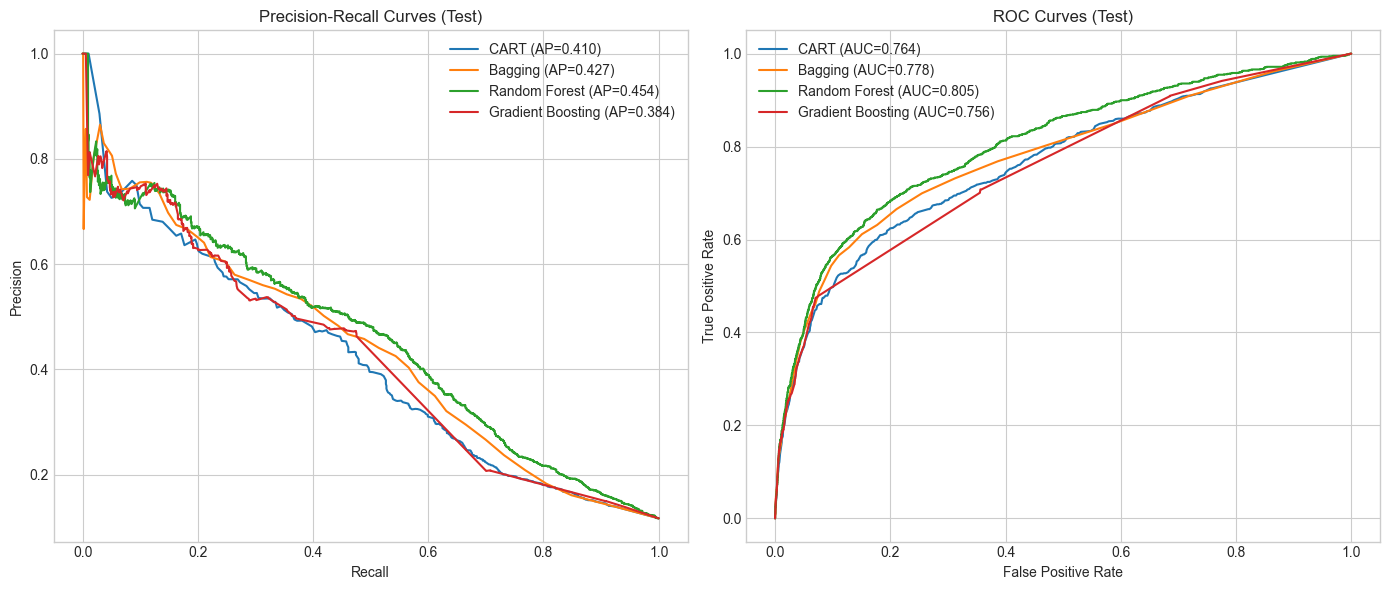


--- Лучшая модель по Test AP: Random Forest ---

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.99      0.94      7985
           1       0.70      0.17      0.27      1058

    accuracy                           0.89      9043
   macro avg       0.80      0.58      0.61      9043
weighted avg       0.88      0.89      0.86      9043



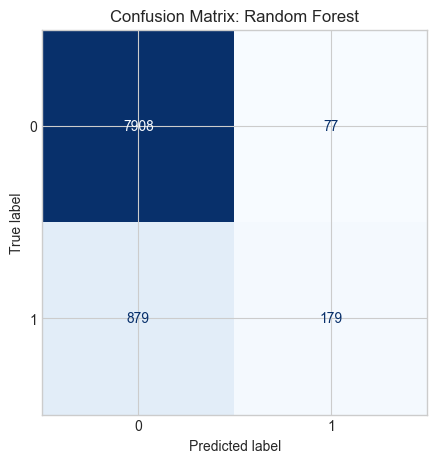

In [14]:
# TODO: постройте на одном рисунке PR- и ROC-кривые настроенных моделей.
# TODO: для модели с лучшим CV average_precision выведите confusion matrix и classification_report.
# 1. Построение PR- и ROC-кривых на одном полотне
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for name, model in tuned_models.items():
    y_score = model_predictions[name]["y_score"]
    
    # Precision-Recall кривая
    precision, recall, _ = precision_recall_curve(y_test, y_score)
    ap = average_precision_score(y_test, y_score)
    axes[0].plot(recall, precision, label=f"{name} (AP={ap:.3f})")
    
    # ROC кривая
    fpr, tpr, _ = roc_curve(y_test, y_score)
    roc_auc = roc_auc_score(y_test, y_score)
    axes[1].plot(fpr, tpr, label=f"{name} (AUC={roc_auc:.3f})")

axes[0].set_title("Precision-Recall Curves (Test)")
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].legend(loc="best")
axes[0].grid(True)

axes[1].set_title("ROC Curves (Test)")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend(loc="best")
axes[1].grid(True)

plt.tight_layout()
plt.show()

# 2. Вывод матрицы ошибок и classification_report для лучшей модели по AP
best_model_name = final_results.loc[0, "Model"]
print(f"\n--- Лучшая модель по Test AP: {best_model_name} ---")

best_preds = model_predictions[best_model_name]["y_pred"]
print("\nClassification Report:")
print(classification_report(y_test, best_preds))

fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay.from_predictions(y_test, best_preds, ax=ax, cmap="Blues", colorbar=False)
plt.title(f"Confusion Matrix: {best_model_name}")
plt.show()

## 7. Interpretation

`feature_importances_` измеряет суммарное уменьшение impurity внутри
конкретной модели. Это не причинный эффект и может быть смещено в пользу
признаков с большим числом вариантов. Поэтому сравните его с permutation
importance на test: здесь по очереди перемешивается один исходный
столбец, а измеряется падение average precision.

Сформулируйте два вывода только по наблюдаемым результатам и отдельно
назовите ограничение интерпретации. Подробнее: [permutation importance
в sklearn](https://scikit-learn.org/stable/modules/permutation_importance.html).

Интерпретация модели: Random Forest


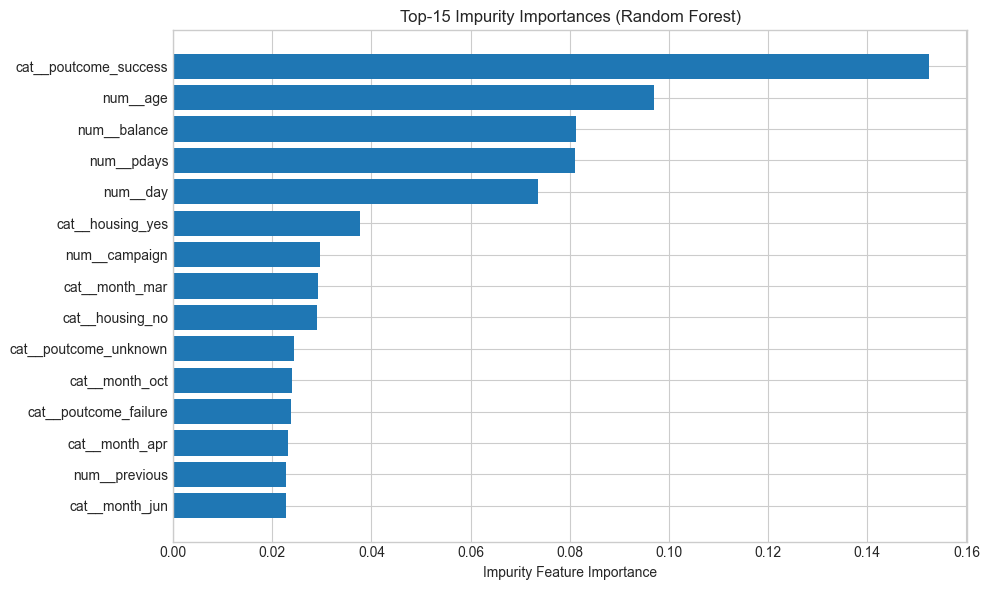

Вычисление permutation importance (может занять полминуты)...


C:\Users\Sergei\AppData\Local\Temp\ipykernel_4640\2204288061.py:45: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


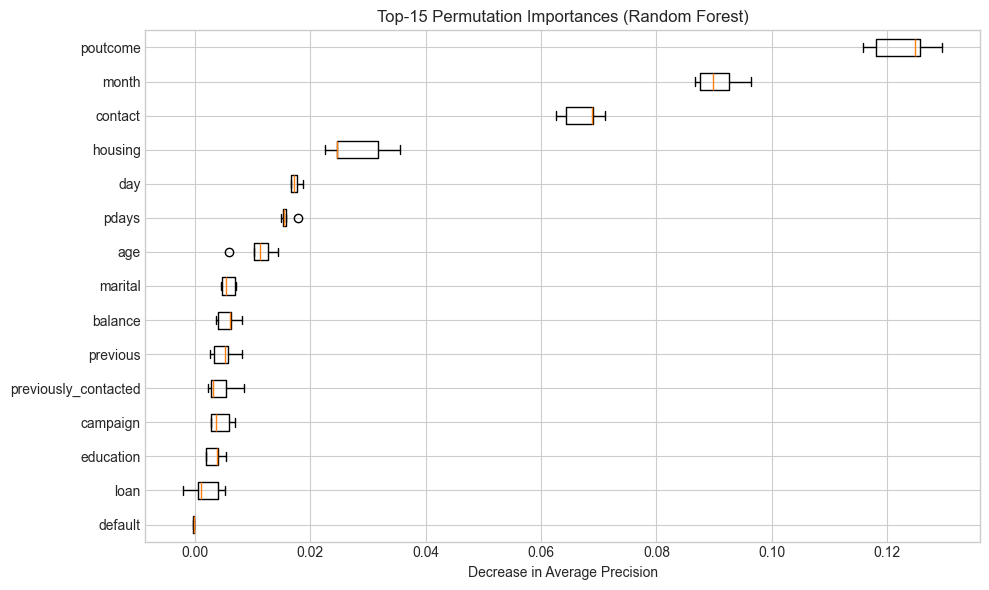

In [15]:
# TODO: постройте top-15 impurity importance для выбранной модели, если атрибут доступен.
# TODO: посчитайте permutation_importance(selected_model, X_test, y_test,
# scoring="average_precision", n_repeats=5, random_state=RANDOM_STATE) и визуализируйте top-15.
from sklearn.inspection import permutation_importance

# Выберем для интерпретации Random Forest или Gradient Boosting (например, Random Forest)
model_name_to_interpret = "Random Forest" if "Random Forest" in tuned_models else list(tuned_models.keys())[1]
selected_model = tuned_models[model_name_to_interpret]

print(f"Интерпретация модели: {model_name_to_interpret}")

# Достаем сам эстиматор из пайплайна (после препроцессора)
estimator = selected_model.named_steps["model"]
preprocessor_fitted = selected_model.named_steps["preprocessor"]

# Получаем названия признаков после One-Hot Encoding
encoded_feature_names = preprocessor_fitted.get_feature_names_out()

# 1. Встроенная важность (feature_importances_)
if hasattr(estimator, "feature_importances_"):
    importances = estimator.feature_importances_
    sorted_idx = np.argsort(importances)[-15:] # топ-15
    
    plt.figure(figsize=(10, 6))
    plt.barh(range(len(sorted_idx)), importances[sorted_idx], align="center")
    plt.yticks(range(len(sorted_idx)), [encoded_feature_names[i] for i in sorted_idx])
    plt.xlabel("Impurity Feature Importance")
    plt.title(f"Top-15 Impurity Importances ({model_name_to_interpret})")
    plt.tight_layout()
    plt.show()

# 2. Permutation Importance на тесте
print("Вычисление permutation importance (может занять полминуты)...")
perm_result = permutation_importance(
    selected_model, X_test, y_test,
    scoring="average_precision",
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

perm_sorted_idx = perm_result.importances_mean.argsort()[-15:]

plt.figure(figsize=(10, 6))
plt.boxplot(
    perm_result.importances[perm_sorted_idx].T,
    vert=False,
    labels=[X_test.columns[i] for i in perm_sorted_idx]
)
plt.xlabel("Decrease in Average Precision")
plt.title(f"Top-15 Permutation Importances ({model_name_to_interpret})")
plt.tight_layout()
plt.show()

## 8. Контролируемый опыт: утечка `duration`

Этот опыт проводится только на `X_train, y_train`. Постройте одинаковый
baseline Random Forest с корректным набором признаков и с добавленной
`duration`, затем сравните CV average precision. Повышение второй
оценки не означает улучшения модели для решения до звонка: оно показывает
использование информации из будущего.

In [16]:
# TODO: получите X_with_duration и оставьте только строки X_train.
# TODO: сравните 3-fold CV AP двух одинаковых RandomForest pipeline: safe и leaky.
# Не используйте X_test и не добавляйте leaky-модель в final_results.
# 1. Получаем данные с duration для тренировок
X_raw_with_dur, y_raw_with_dur = prepare_domain_features(raw_data, include_duration=True)

# Берем ровно те же индексы, что и для train_val сплита
X_train_val_dur = X_raw_with_dur.loc[X_train_val.index]

# Выделяем числовые и категориальные признаки с учетом duration
num_cols_dur = X_train_val_dur.select_dtypes(include=[np.number]).columns.tolist()
cat_cols_dur = X_train_val_dur.select_dtypes(include=["object", "category", "str"]).columns.tolist()

# Создаем препроцессор для leaky-пайплайна
leaky_preprocessor = build_preprocessor(num_cols_dur, cat_cols_dur)

def make_leaky_pipeline(model):
    return Pipeline(steps=[
        ("preprocessor", leaky_preprocessor),
        ("model", model)
    ])

# 2. Создаем две модели: safe (без duration) и leaky (с duration)
safe_rf = make_model_pipeline(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1))
leaky_rf = make_leaky_pipeline(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1))

# 3. Сравниваем 3-fold CV Average Precision
print("Оценка safe-модели (без duration)...")
safe_scores = cross_validate(safe_rf, X_train_val, y_train_val, cv=CV, scoring="average_precision", n_jobs=-1)

print("Оценка leaky-модели (с утечкой duration)...")
leaky_scores = cross_validate(leaky_rf, X_train_val_dur, y_train_val, cv=CV, scoring="average_precision", n_jobs=-1)

print("\n--- Результаты контролируемого опыта ---")
print(f"Safe Random Forest AP (CV):   {safe_scores['test_score'].mean():.4f}")
print(f"Leaky Random Forest AP (CV):  {leaky_scores['test_score'].mean():.4f}")
print("Вывод: добавление duration резко повышает метрику, но создает недопустимую утечку данных (data leakage).")

Оценка safe-модели (без duration)...
Оценка leaky-модели (с утечкой duration)...

--- Результаты контролируемого опыта ---
Safe Random Forest AP (CV):   0.4163
Leaky Random Forest AP (CV):  0.6046
Вывод: добавление duration резко повышает метрику, но создает недопустимую утечку данных (data leakage).


## 9. Model card и итог

1. **Задача и объект наблюдения:** Бинарная классификация на основе набора данных UCI Bank Marketing (45 211 строк, 16 входных признаков) с целью прогнозирования согласия клиента банка на оформление срочного вклада после маркетинговой кампании.
2. **Источник данных и этика применения:** Данные получены из UCI Machine Learning Repository (лицензия CC BY 4.0). Набор отражает исторические решения конкретной организации и не является универсальным правилом; модель не заменяет человека и требует проверки стоимости ошибок.
3. **Предотвращение утечки данных (Data Leakage):** Признак `duration` (длительность звонка) исключен из основной задачи, так как он недоступен в момент принятия решения о звонке. Контролируемый опыт подтвердил, что его добавление искусственно завышает метрики качества.
4. **Особенность признака `pdays`:** Значение `-1` было заменено на пропуск (`NaN`), а также добавлен бинарный флаг `previously_contacted` для корректного учета факта предыдущих контактов. Все шаги предобработки (импутация, One-Hot Encoding) инкапсулированы в `Pipeline` и `ColumnTransformer`.
5. **Стратегия валидации:** Выполнено стратифицированное разбиение данных с фиксацией `random_state = 42`. Подбор параметров и оценка проводились на обучающей выборке с использованием трёхфолдовой кросс-валидации (`StratifiedKFold`).
6. **Метрика успеха:** Основной метрикой выбрана **Average Precision (AP)** из-за сильного дисбаланса классов. Дополнительно фиксировались ROC-AUC, Precision, Recall, F1 и Balanced Accuracy.
7. **Моделирование и тюнинг:** Проведено честное сравнение baseline-моделей (Prior Baseline, CART, Bagging, Random Forest, Gradient Boosting) с последующей настройкой деревьев через `GridSearchCV` и ансамблей через `RandomizedSearchCV`.
8. **Интерпретация результатов:** Важность признаков по уменьшению неоднородности (`impurity importance`) сопоставлена с `permutation importance` на тестовой выборке, что позволило нивелировать смещение в пользу признаков с большим числом уникальных значений.
9. **Ограничения и внедрение:** Перед практическим внедрением модели необходимо оценить сдвиг признаков (data drift), стабильность распределений и экономическую целесообразность ошибок классификации.